<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/Multi_LR_wineQuli.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
df= pd.read_csv("winequality_red.csv")
df

,"fixed acidity;""volatile acidity"";""citric acid"";""residual sugar"";""chlorides"";""free sulfur dioxide"";""total sulfur dioxide"";""density"";""pH"";""sulphates"";""alcohol"";""quality"""
0,7.4;0.7;0;1.9;0.076;11;34;0.9978;3.51;0.56;9.4;5
1,7.8;0.88;0;2.6;0.098;25;67;0.9968;3.2;0.68;9.8;5
2,7.8;0.76;0.04;2.3;0.092;15;54;0.997;3.26;0.65;...
3,11.2;0.28;0.56;1.9;0.075;17;60;0.998;3.16;0.58...
4,7.4;0.7;0;1.9;0.076;11;34;0.9978;3.51;0.56;9.4;5
...,...
1594,6.2;0.6;0.08;2;0.09;32;44;0.9949;3.45;0.58;10.5;5
1595,5.9;0.55;0.1;2.2;0.062;39;51;0.99512;3.52;0.76...
1596,6.3;0.51;0.13;2.3;0.076;29;40;0.99574;3.42;0.7...
1597,5.9;0.645;0.12;2;0.075;32;44;0.99547;3.57;0.71...


In [71]:
df= pd.read_csv("winequality_red.csv",sep=";")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [72]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [73]:
df.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [74]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [75]:
df[["density","alcohol"]].duplicated().sum()

np.int64(454)

In [76]:
df["quality"].unique()

array([5, 6, 7, 4, 8, 3])

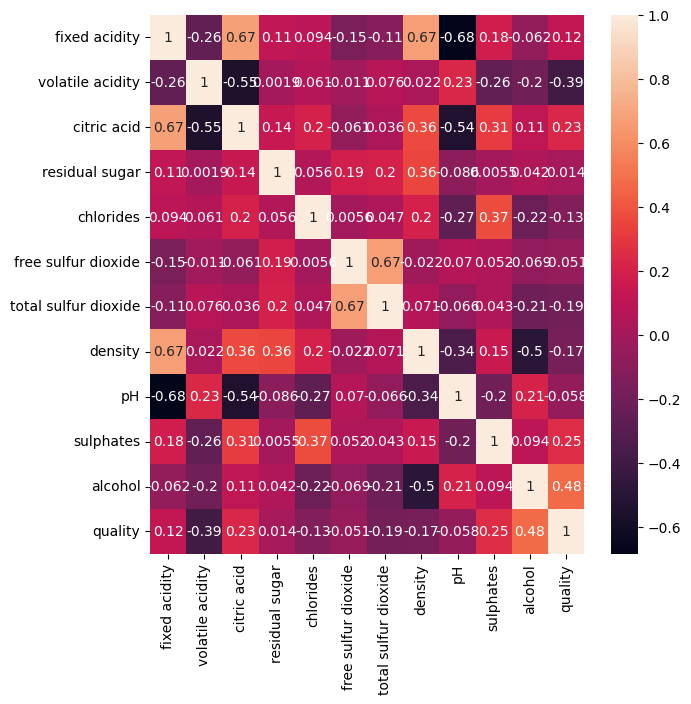

In [77]:
crr_metrx= df.corr()
plt.figure(figsize=(7,7))
sns.heatmap(crr_metrx,annot=True)
plt.show()

In [78]:
X=df.drop("quality",axis=1)
y=df["quality"]

In [79]:
df["quality"].value_counts()

,count
quality,
5,681
6,638
7,199
4,53
8,18
3,10


In [80]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [81]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
#library now automatically uses the multinomial approach for problems with 3 or more classes
lr.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [82]:
from sklearn.preprocessing import StandardScaler
sc= StandardScaler()
X_train_scaled= sc.fit_transform(X_train)
X_test_scaled= sc.transform(X_test)
lr.fit(X_train_scaled,y_train)

LogisticRegression()

In [83]:
y_pred = lr.predict(X_test_scaled)
y_pred

array([6, 5, 5, 6, 5, 6, 5, 5, 5, 6, 5, 5, 5, 5, 5, 6, 5, 5, 7, 6, 6, 6,
       6, 5, 5, 6, 5, 6, 6, 5, 6, 5, 6, 6, 6, 5, 5, 6, 5, 6, 5, 5, 5, 6,
       6, 5, 6, 6, 5, 5, 5, 6, 5, 6, 6, 5, 5, 5, 5, 5, 5, 6, 5, 6, 6, 5,
       6, 5, 5, 6, 6, 5, 6, 6, 5, 6, 6, 6, 5, 6, 5, 6, 6, 5, 5, 5, 5, 5,
       7, 5, 5, 5, 6, 7, 5, 6, 5, 5, 6, 5, 7, 6, 6, 6, 6, 6, 6, 6, 7, 6,
       5, 5, 5, 5, 6, 6, 5, 5, 6, 6, 7, 5, 6, 6, 7, 6, 6, 5, 5, 6, 6, 6,
       5, 6, 6, 6, 5, 6, 5, 6, 5, 5, 5, 5, 5, 7, 5, 6, 5, 6, 6, 5, 5, 5,
       5, 5, 5, 5, 6, 6, 6, 5, 5, 6, 5, 6, 6, 6, 5, 6, 6, 5, 5, 7, 7, 5,
       6, 5, 6, 7, 6, 5, 6, 5, 5, 6, 6, 5, 5, 5, 6, 5, 5, 5, 6, 6, 6, 5,
       5, 5, 6, 5, 5, 5, 6, 5, 5, 6, 6, 6, 5, 6, 5, 6, 7, 6, 6, 6, 6, 6,
       6, 6, 5, 5, 5, 6, 6, 6, 7, 6, 6, 5, 6, 6, 5, 6, 5, 6, 6, 5, 5, 5,
       5, 6, 5, 5, 7, 6, 6, 6, 5, 5, 5, 5, 6, 5, 5, 5, 5, 6, 6, 6, 6, 5,
       6, 6, 5, 6, 5, 7, 5, 5, 5, 6, 5, 6, 6, 5, 6, 5, 6, 5, 5, 6, 6, 6,
       6, 5, 5, 5, 6, 7, 6, 5, 5, 5, 6, 5, 5, 7, 5,

In [84]:
from sklearn.metrics import accuracy_score    #score
from sklearn.metrics import precision_score    #score
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import recall_score    #score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import f1_score    #score
from sklearn.metrics import confusion_matrix     #matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report  #report

In [85]:
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred,average="weighted"))
print(recall_score(y_test,y_pred,average="weighted"))
print(f1_score(y_test,y_pred,average="weighted"))
print(classification_report(y_test,y_pred))
cof_metx = confusion_matrix(y_test,y_pred)
print(cof_metx)

0.590625
0.5695246022937477
0.590625
0.5672975809413863
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       136
           6       0.54      0.61      0.57       128
           7       0.71      0.30      0.42        40
           8       0.00      0.00      0.00         3

    accuracy                           0.59       320
   macro avg       0.31      0.27      0.28       320
weighted avg       0.57      0.59      0.57       320

[[ 0  0  1  1  0  0]
 [ 0  0 10  1  0  0]
 [ 0  0 99 36  1  0]
 [ 0  0 47 78  3  0]
 [ 0  0  2 26 12  0]
 [ 0  0  0  2  1  0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

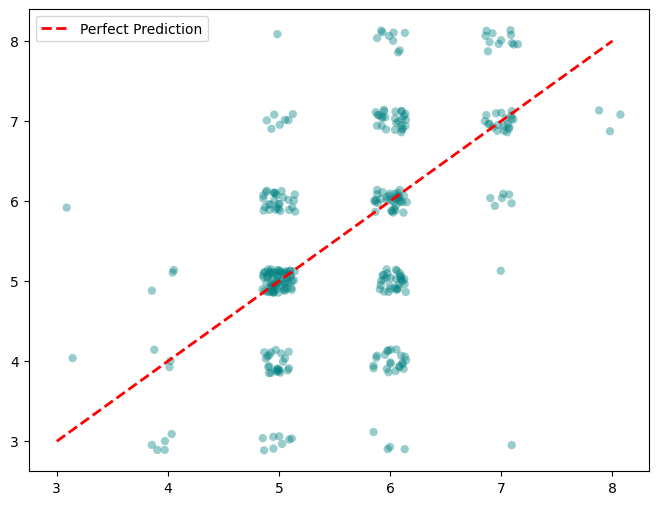

In [86]:

plt.figure(figsize=(8, 6))

# Add small random noise to make overlapping points visible
jitter = 0.15
y_test_jitter = y_test + np.random.uniform(-jitter, jitter, size=len(y_test))
y_pred_jitter = y_pred_new + np.random.uniform(-jitter, jitter, size=len(y_pred_new))
plt.scatter(y_test_jitter, y_pred_jitter, alpha=0.4, color='teal', edgecolors='none')
# Perfect prediction line
plt.plot([3, 8], [3, 8], color='red', linestyle='--', lw=2, label='Perfect Prediction')
plt.legend()
plt.show()

In [88]:
lr_m = LogisticRegression(multi_class="ovr",solver="newton-cg")
lr_m.fit(X_train_scaled,y_train)
y_pred = lr_m.predict(X_test_scaled)
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred,average="weighted"))
print(recall_score(y_test,y_pred,average="weighted"))
print(f1_score(y_test,y_pred,average="weighted"))
print(classification_report(y_test,y_pred))
cof_metx = confusion_matrix(y_test,y_pred)
print(cof_metx)

0.584375
0.5676550031053353
0.584375


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


0.546082145875715
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.76      0.69       136
           6       0.53      0.61      0.57       128
           7       0.71      0.12      0.21        40
           8       0.00      0.00      0.00         3

    accuracy                           0.58       320
   macro avg       0.31      0.25      0.24       320
weighted avg       0.57      0.58      0.55       320

[[  0   0   1   1   0   0]
 [  0   0  10   1   0   0]
 [  0   0 104  31   1   0]
 [  0   0  50  78   0   0]
 [  0   0   2  33   5   0]
 [  0   0   0   2   1   0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [89]:
from sklearn.pipeline import make_pipeline
#1. Create the pipeline with scaling and balanced weights
pipe=make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight='balanced',
                                      max_iter=200,
                                      random_state=42))
#2)Fit and predict
pipe.fit(X_train,y_train)
y_pred_new=pipe.predict(X_test)
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred,average="weighted"))
print(recall_score(y_test,y_pred,average="weighted"))
print(f1_score(y_test,y_pred,average="weighted"))
print(classification_report(y_test,y_pred))
cof_metx = confusion_matrix(y_test,y_pred)
print(cof_metx)

0.584375
0.5676550031053353
0.584375
0.546082145875715
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.76      0.69       136
           6       0.53      0.61      0.57       128
           7       0.71      0.12      0.21        40
           8       0.00      0.00      0.00         3

    accuracy                           0.58       320
   macro avg       0.31      0.25      0.24       320
weighted avg       0.57      0.58      0.55       320

[[  0   0   1   1   0   0]
 [  0   0  10   1   0   0]
 [  0   0 104  31   1   0]
 [  0   0  50  78   0   0]
 [  0   0   2  33   5   0]
 [  0   0   0   2   1   0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m